# Smart Home Energy Consumption Prediction

## Project Overview

This project investigates household appliance energy consumption using environmental sensor measurements and weather-related variables.

The analysis uses the UCI Appliances Energy Prediction dataset to explore energy consumption patterns, identify influential factors, and develop machine learning models for predicting appliance electricity consumption.

### Project Objectives

1. Explore and understand the smart home energy dataset.
2. Clean and preprocess the data.
3. Analyze energy consumption patterns and environmental influences.
4. Engineer relevant features for predictive modeling.
5. Develop and compare machine learning models.
6. Evaluate predictive performance using appropriate regression metrics.
7. Interpret the results and identify opportunities for improved household energy management.

### Dataset

**Source:** UCI Machine Learning Repository — Appliances Energy Prediction

**Target variable:** `Appliances` (Wh)

**Data frequency:** 10-minute intervals

**Study period:** Approximately 4.5 months in 2016.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All essential libraries imported successfully!")

All essential libraries imported successfully!


## 1. Data Loading and Initial Inspection

### 1.1 Loading the Dataset

The Appliances Energy Prediction dataset is loaded using Pandas. The initial inspection will confirm the dataset dimensions, column names, and sample observations before preprocessing.

In [2]:
# Load the Smart Home Energy dataset

from pathlib import Path

data_path = Path("../data/UCI Appliances Energy Prediction_energydata_complete.csv")

df = pd.read_csv(data_path, parse_dates=["date"])

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())


Dataset loaded successfully!
Number of rows: 19,735
Number of columns: 29


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097


### 1.2 Dataset Structure and Data Types

This section examines the dataset's column names, data types, and completeness to understand its structure before data cleaning and preprocessing.

In [3]:
# Inspect dataset structure and data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         19735 non-null  datetime64[ns]
 1   Appliances   19735 non-null  int64         
 2   lights       19735 non-null  int64         
 3   T1           19735 non-null  float64       
 4   RH_1         19735 non-null  float64       
 5   T2           19735 non-null  float64       
 6   RH_2         19735 non-null  float64       
 7   T3           19735 non-null  float64       
 8   RH_3         19735 non-null  float64       
 9   T4           19735 non-null  float64       
 10  RH_4         19735 non-null  float64       
 11  T5           19735 non-null  float64       
 12  RH_5         19735 non-null  float64       
 13  T6           19735 non-null  float64       
 14  RH_6         19735 non-null  float64       
 15  T7           19735 non-null  float64       
 16  RH_7

### 1.3 Missing Values and Duplicate Records

This section checks for missing values, duplicate rows, and duplicate timestamps to assess data quality before preprocessing.

In [4]:
# Check missing values and duplicate records

print("Total missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

print("Duplicate timestamps:", df["date"].duplicated().sum())


Total missing values: 0
Duplicate rows: 0
Duplicate timestamps: 0


### 1.4 Timestamp Continuity

This section verifies that the dataset is chronologically ordered and that observations occur at the expected 10-minute intervals.

In [5]:
# Check chronological order and timestamp continuity

time_diff = df["date"].diff().dropna()

print("Chronologically ordered:", df["date"].is_monotonic_increasing)

print("First observation:", df["date"].min())

print("Last observation:", df["date"].max())

print("Expected interval:", pd.Timedelta(minutes=10))

print("Irregular intervals:", (time_diff != pd.Timedelta(minutes=10)).sum())

Chronologically ordered: True
First observation: 2016-01-11 17:00:00
Last observation: 2016-05-27 18:00:00
Expected interval: 0 days 00:10:00
Irregular intervals: 0


### 1.5 Data Quality Assessment Summary

The initial data quality assessment confirmed that the Appliances Energy Prediction dataset contains 19,735 observations and 29 variables, covering the period from 11 January 2016 to 27 May 2016.

The following findings were established:

- All 29 variables contain complete observations, with no missing values.
- No duplicate records were identified.
- No duplicate timestamps were detected.
- The observations are arranged in chronological order.
- The dataset maintains a consistent 10-minute measurement interval, with no irregular intervals.

**Conclusion:** The dataset is structurally complete and temporally consistent. Consequently, no missing-value imputation, duplicate removal, or timestamp correction is necessary.

Further assessment of variable distributions, potential outliers, and feature suitability will be performed during exploratory data analysis and preprocessing.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive Statistics

This section summarizes the numerical variables in the smart home energy dataset using descriptive statistics.

The analysis examines central tendency, variability, and value ranges to establish an initial understanding of appliance energy consumption and environmental conditions.

In [6]:
# Generate descriptive statistics for numerical variables

descriptive_stats = df.describe().T

display(descriptive_stats.round(2))

,count,mean,min,25%,50%,75%,max,std
date,19735,2016-03-20 05:30:00,2016-01-11 17:00:00,2016-02-14 23:15:00,2016-03-20 05:30:00,2016-04-23 11:45:00,2016-05-27 18:00:00,NaN
Appliances,19735.0,97.694958,10.0,50.0,60.0,100.0,1080.0,102.524891
lights,19735.0,3.801875,0.0,0.0,0.0,0.0,70.0,7.935988
T1,19735.0,21.686571,16.79,20.76,21.6,22.6,26.26,1.606066
RH_1,19735.0,40.259739,27.023333,37.333333,39.656667,43.066667,63.36,3.979299
T2,19735.0,20.341219,16.1,18.79,20.0,21.5,29.856667,2.192974
RH_2,19735.0,40.42042,20.463333,37.9,40.5,43.26,56.026667,4.069813
T3,19735.0,22.267611,17.2,20.79,22.1,23.29,29.236,2.006111
RH_3,19735.0,39.2425,28.766667,36.9,38.53,41.76,50.163333,3.254576
T4,19735.0,20.855335,15.1,19.53,20.666667,22.1,26.2,2.042884


### 2.2 Distribution of Appliance Energy Consumption

This section examines the distribution of appliance energy consumption using a histogram and boxplot.

The objective is to understand the typical consumption range, distribution shape, and presence of unusually high consumption values.

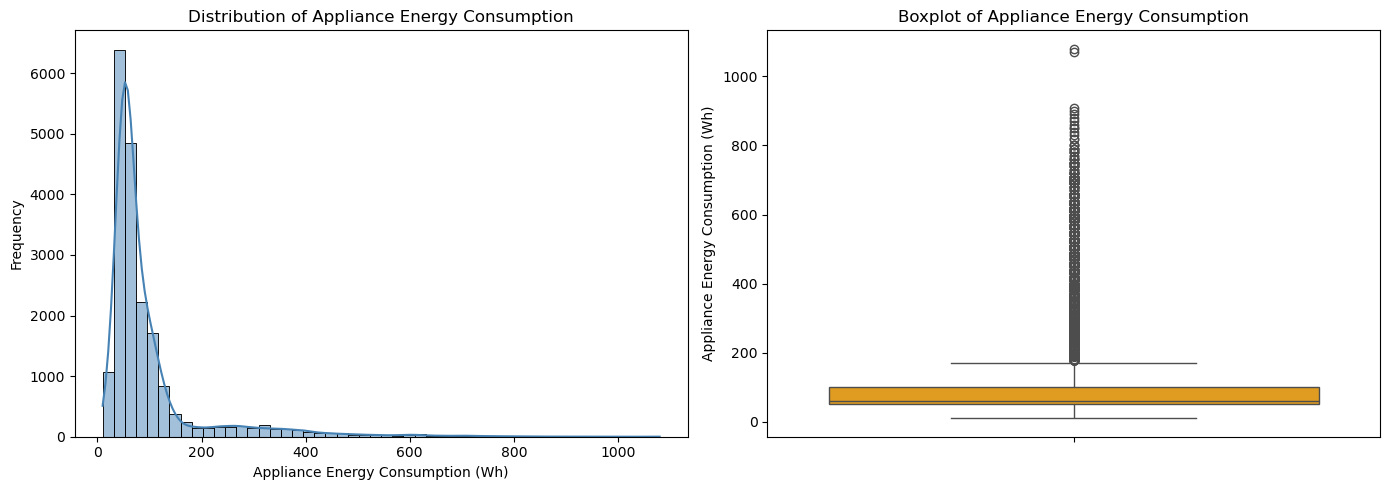

In [7]:
# Visualize appliance energy consumption distribution

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["Appliances"],
    bins=50,
    kde=True,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Appliance Energy Consumption")
axes[0].set_xlabel("Appliance Energy Consumption (Wh)")
axes[0].set_ylabel("Frequency")

sns.boxplot(
    y=df["Appliances"],
    color="orange",
    ax=axes[1]
)

axes[1].set_title("Boxplot of Appliance Energy Consumption")
axes[1].set_ylabel("Appliance Energy Consumption (Wh)")

plt.tight_layout()

plt.savefig(
    "../figure/appliance_energy_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.3 Daily Appliance Energy Consumption Trends

This section examines how average appliance energy consumption changes over time.

Daily average consumption is calculated from the original 10-minute measurements to identify temporal patterns, fluctuations, and periods of unusually high or low demand.

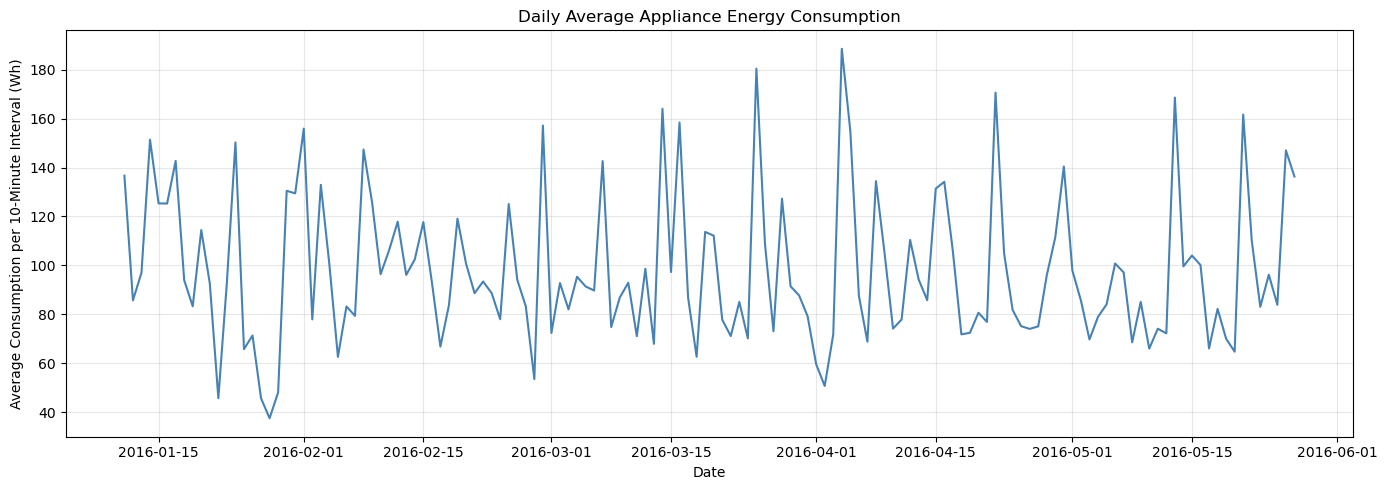

In [8]:
# Calculate daily average appliance energy consumption

daily_appliances = (
    df.set_index("date")["Appliances"]
    .resample("D")
    .mean()
)

# Plot daily average appliance consumption

plt.figure(figsize=(14, 5))

plt.plot(
    daily_appliances.index,
    daily_appliances.values,
    color="steelblue",
    linewidth=1.5
)

plt.title("Daily Average Appliance Energy Consumption")
plt.xlabel("Date")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/daily_appliance_energy_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.4 Hourly Appliance Energy Consumption Profile

This section examines the average appliance energy consumption at each hour of the day.

The objective is to identify daily consumption patterns and determine whether appliance energy demand varies systematically across different hours.

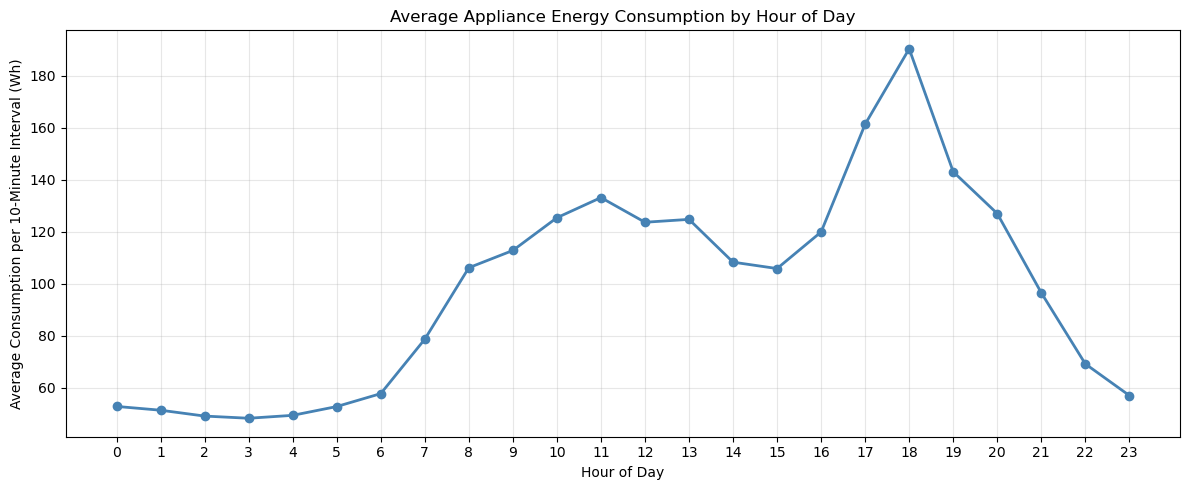

Highest consumption hour: 18
Lowest consumption hour: 3


In [9]:
# Calculate average appliance consumption by hour of day

hourly_profile = (
    df.groupby(df["date"].dt.hour)["Appliances"]
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_profile.index,
    hourly_profile.values,
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Average Appliance Energy Consumption by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/hourly_appliance_energy_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Highest consumption hour:", hourly_profile.idxmax())
print("Lowest consumption hour:", hourly_profile.idxmin())

### 2.5 Correlation Analysis

Correlation analysis helps identify relationships between appliance energy consumption and environmental variables, including indoor temperature, humidity, and outdoor weather conditions.

Pearson correlation coefficients range from -1 to +1, where positive values indicate a positive linear relationship, negative values indicate a negative linear relationship, and values close to zero indicate a weak linear relationship.

In [10]:
# Section 2.5.1: Correlation with Appliance Energy Consumption

# Calculate Pearson correlation coefficients for numerical variables
correlation_matrix = df.select_dtypes(include="number").corr()

# Extract correlations with the target variable
appliance_correlations = (
    correlation_matrix["Appliances"]
    .drop("Appliances")
    .sort_values(ascending=False)
)

# Display correlation coefficients
display(appliance_correlations.to_frame(name="Correlation with Appliances").round(3))

,Correlation with Appliances
lights,0.197
T2,0.120
T6,0.118
T_out,0.099
Windspeed,0.087
RH_1,0.086
T3,0.085
T1,0.055
T4,0.040
T8,0.040


### 2.5.2 Visualization of Correlations with Appliance Energy Consumption

A horizontal bar chart is used to visualize the strength and direction of Pearson correlations between appliance energy consumption and the numerical predictor variables.

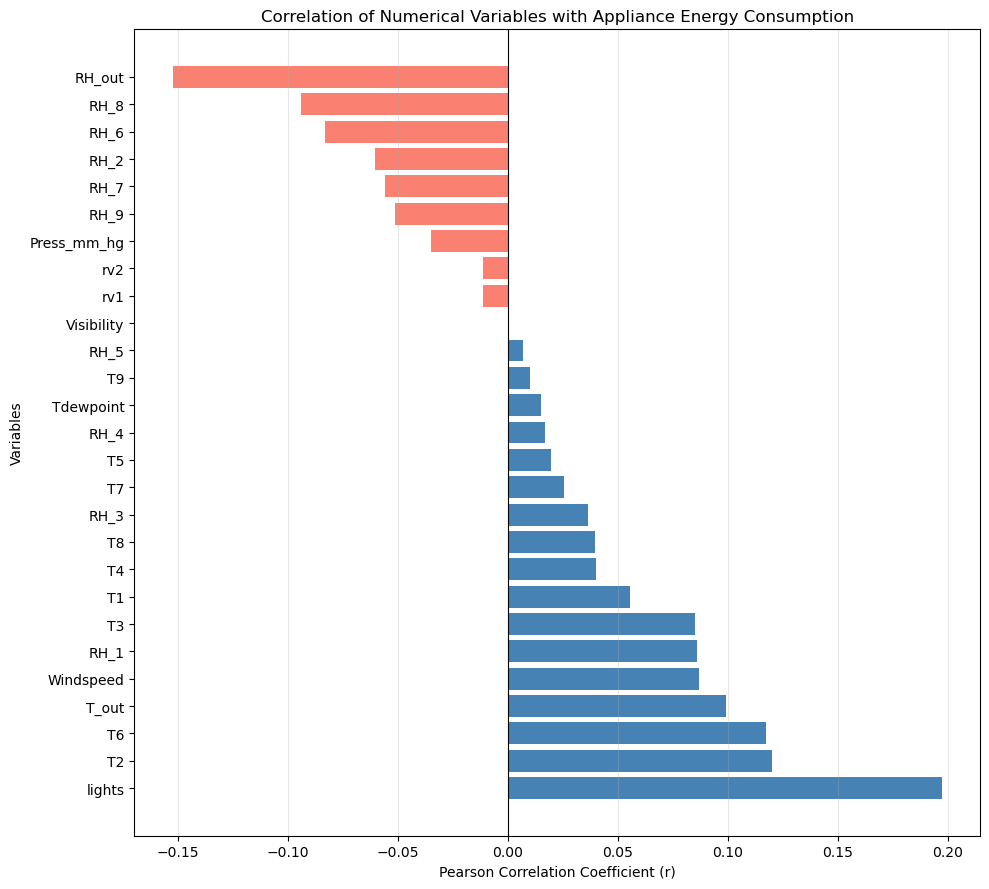

In [11]:
# Section 2.5.2: Correlation Visualization

plt.figure(figsize=(10, 9))

colors = [
    "steelblue" if value >= 0 else "salmon"
    for value in appliance_correlations.values
]

plt.barh(
    appliance_correlations.index,
    appliance_correlations.values,
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Correlation of Numerical Variables with Appliance Energy Consumption")
plt.xlabel("Pearson Correlation Coefficient (r)")
plt.ylabel("Variables")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/appliance_correlation_bar_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.5.3 Key Findings from Correlation Analysis

The correlation analysis revealed that most individual environmental and weather variables have weak linear relationships with appliance energy consumption.

Key observations include:

- Lighting consumption showed the strongest positive correlation with appliance energy consumption (r = 0.197).
- Outdoor relative humidity (RH_out) showed the strongest negative correlation (approximately r = -0.153).
- Indoor temperature measurements (T2 and T6) exhibited weak positive correlations.
- Most other variables showed correlations close to zero, indicating limited individual linear relationships with appliance consumption.

These findings suggest that appliance energy consumption may depend on a combination of environmental conditions, household activity patterns, and time-related factors.

Although individual correlations are weak, the variables may still contribute useful information to machine learning models through nonlinear relationships and interactions.

Correlation does not establish causation.

### 2.6 Weekday vs. Weekend Energy Consumption

This analysis examines whether household appliance energy consumption differs between weekdays and weekends.

Understanding these differences may help identify household activity patterns and support the development of time-based features for machine learning models.

In [12]:
# Section 2.6.1: Weekday vs. Weekend Energy Consumption

# Classify observations as Weekday or Weekend
df["Day_Type"] = np.where(
    df["date"].dt.dayofweek < 5,
    "Weekday",
    "Weekend"
)

# Calculate average appliance consumption by day type
day_type_consumption = (
    df.groupby("Day_Type")["Appliances"]
    .agg(["mean", "median", "std", "count"])
    .reindex(["Weekday", "Weekend"])
)

# Display summary statistics
display(day_type_consumption.round(2))

,mean,median,std,count
Day_Type,,,,
Weekday,96.59,60.0,103.09,14263
Weekend,100.58,70.0,101.00,5472


### 2.6.2 Visualization of Weekday vs. Weekend Energy Consumption

This visualization compares average appliance energy consumption during weekdays and weekends to identify potential differences associated with household activity patterns.

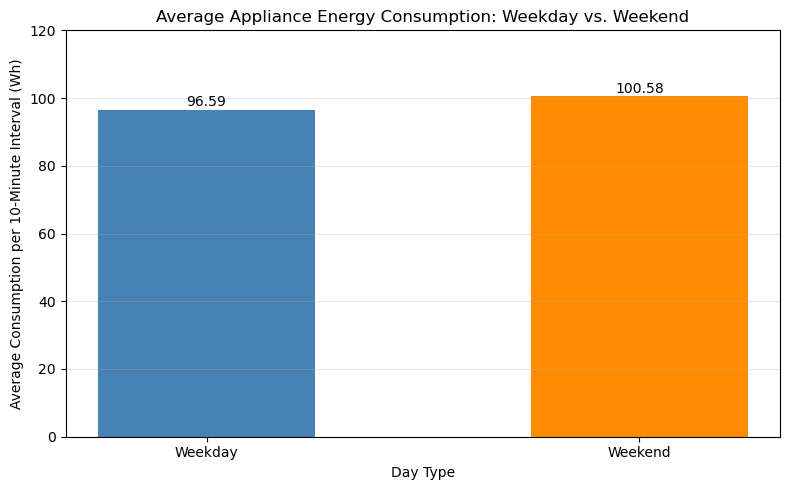

In [13]:
# Section 2.6.2: Weekday vs. Weekend Consumption Visualization

plt.figure(figsize=(8, 5))

bars = plt.bar(
    day_type_consumption.index,
    day_type_consumption["mean"],
    color=["steelblue", "darkorange"],
    width=0.5
)

# Add consumption values above the bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}",
        ha="center"
    )

plt.title("Average Appliance Energy Consumption: Weekday vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Consumption per 10-Minute Interval (Wh)")
plt.ylim(0, 120)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figure/weekday_weekend_energy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 2.6.3 Key Findings: Weekday vs. Weekend Consumption

The analysis revealed a modest difference in appliance energy consumption between weekdays and weekends.

- Average weekday consumption was 96.59 Wh per 10-minute interval, compared with 100.58 Wh during weekends.
- Weekend consumption was approximately 4.1% higher than weekday consumption.
- Median consumption was also higher during weekends (70 Wh) than weekdays (60 Wh).
- Both groups exhibited substantial variability, suggesting that appliance consumption is influenced by factors beyond the day type alone.

These findings indicate that weekday/weekend classification may be useful as a time-based feature in subsequent machine learning models. However, further analysis is needed to determine its predictive importance.

### 2.7 High-Consumption Events and Outlier Analysis

This section investigates unusually high appliance energy consumption readings using the Interquartile Range (IQR) method.

The objective is to quantify the frequency of high-consumption events and assess their potential importance for subsequent predictive modeling.

In [14]:
# Section 2.7.1: Identifying High-Consumption Events

# Calculate the interquartile range
Q1 = df["Appliances"].quantile(0.25)
Q3 = df["Appliances"].quantile(0.75)

IQR = Q3 - Q1

# Calculate the upper outlier threshold
upper_threshold = Q3 + 1.5 * IQR

# Identify unusually high consumption readings
high_consumption = df[df["Appliances"] > upper_threshold]

# Calculate their frequency
high_count = len(high_consumption)
high_percentage = (high_count / len(df)) * 100

# Display results
print(f"First Quartile (Q1): {Q1:.2f} Wh")
print(f"Third Quartile (Q3): {Q3:.2f} Wh")
print(f"Interquartile Range (IQR): {IQR:.2f} Wh")
print(f"Upper Outlier Threshold: {upper_threshold:.2f} Wh")
print(f"High-Consumption Observations: {high_count}")
print(f"Percentage of Observations: {high_percentage:.2f}%")

First Quartile (Q1): 50.00 Wh
Third Quartile (Q3): 100.00 Wh
Interquartile Range (IQR): 50.00 Wh
Upper Outlier Threshold: 175.00 Wh
High-Consumption Observations: 2138
Percentage of Observations: 10.83%


### 2.7.2 Key Findings from High-Consumption Event Analysis

The Interquartile Range (IQR) method identified 2,138 appliance energy consumption observations exceeding the upper threshold of 175 Wh per 10-minute interval. These observations represent approximately 10.83% of the dataset.

The relatively high proportion of observations above the threshold suggests that elevated appliance energy consumption occurs frequently enough to warrant attention during predictive modeling.

However, observations classified as outliers using the IQR method are not necessarily measurement errors. They may represent genuine household activities involving increased appliance usage.

**Decision:** High-consumption observations will be retained during exploratory analysis and initial model development. Their influence on predictive performance will be evaluated during model assessment.


### 2.8 Exploratory Data Analysis Summary

The exploratory data analysis provided important insights into household appliance energy consumption patterns and their relationships with environmental and time-related variables.

**Key Findings**

1. **Energy Consumption Distribution**
   - Appliance energy consumption is strongly right-skewed, with most observations concentrated at relatively low consumption levels.
   - Occasional high-consumption events contribute to substantial variability in energy usage.

2. **Daily and Hourly Consumption Patterns**
   - Daily average appliance consumption fluctuates considerably throughout the observation period.
   - Hourly analysis revealed the highest average consumption around 18:00 and the lowest around 03:00, suggesting that household activity schedules influence electricity demand.

3. **Correlation Analysis**
   - Lighting consumption exhibited the strongest positive linear correlation with appliance energy consumption (r = 0.197).
   - Outdoor relative humidity showed the strongest negative correlation (approximately r = -0.153).
   - Most environmental variables exhibited weak individual linear correlations, suggesting that nonlinear relationships and interactions may be important.

4. **Weekday vs. Weekend Consumption**
   - Average weekend appliance consumption was 100.58 Wh per 10-minute interval, compared with 96.59 Wh on weekdays.
   - The approximately 4.1% difference suggests that day type may provide useful information for prediction.

5. **High-Consumption Events**
   - The IQR method identified 2,138 observations (10.83%) exceeding 175 Wh per 10-minute interval.
   - These observations will be retained for initial modeling because they may represent genuine household energy usage.

**Implications for Predictive Modeling**

The findings indicate that appliance energy consumption may depend on a combination of environmental conditions, household activity patterns, and temporal characteristics.

The next phase will focus on feature engineering, including extracting useful time-related variables and preparing the dataset for machine learning.

Care will be taken to prevent data leakage and preserve the chronological structure of the observations during model development and evaluation.


## 3. Feature Engineering

Feature engineering transforms existing dataset variables into useful predictors for machine learning.

In this section, we will create time-based features, investigate potentially redundant variables, and prepare the dataset for predictive modeling while preserving its chronological structure.

### 3.1 Time-Based Feature Extraction

The timestamp column contains useful information about household energy consumption patterns. We will extract hour, day of week, month, and weekend indicators to help machine learning models identify temporal patterns.

In [15]:
# Section 3.1: Time-Based Feature Extraction

# Create a separate dataset for feature engineering
df_model = df.copy()

# Extract time-related features
df_model["hour"] = df_model["date"].dt.hour
df_model["day_of_week"] = df_model["date"].dt.dayofweek
df_model["month"] = df_model["date"].dt.month

# Weekend indicator: 1 = Weekend, 0 = Weekday
df_model["is_weekend"] = (
    df_model["day_of_week"] >= 5
).astype(int)

# Display the newly created features
display(
    df_model[
        ["date", "hour", "day_of_week", "month", "is_weekend"]
    ].head(10)
)

,date,hour,day_of_week,month,is_weekend
0,2016-01-11 17:00:00,17,0,1,0
1,2016-01-11 17:10:00,17,0,1,0
2,2016-01-11 17:20:00,17,0,1,0
3,2016-01-11 17:30:00,17,0,1,0
4,2016-01-11 17:40:00,17,0,1,0
5,2016-01-11 17:50:00,17,0,1,0
6,2016-01-11 18:00:00,18,0,1,0
7,2016-01-11 18:10:00,18,0,1,0
8,2016-01-11 18:20:00,18,0,1,0
9,2016-01-11 18:30:00,18,0,1,0


### 3.2 Cyclical Encoding of Time Features

Time-related variables such as hour of day and day of week follow repeating cycles.

To represent these patterns appropriately, sine and cosine transformations are applied to the hour and day-of-week features.

This encoding preserves the cyclical relationship between time values and may improve the ability of machine learning models to identify recurring energy consumption patterns.

In [16]:
# Section 3.2: Cyclical Encoding of Time Features

# Encode hour of day (24-hour cycle)
df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["hour"] / 24
)

# Encode day of week (7-day cycle)
df_model["day_sin"] = np.sin(
    2 * np.pi * df_model["day_of_week"] / 7
)

df_model["day_cos"] = np.cos(
    2 * np.pi * df_model["day_of_week"] / 7
)

# Display the new cyclical features
display(
    df_model[
        ["hour", "hour_sin", "hour_cos",
         "day_of_week", "day_sin", "day_cos"]
    ].head(10).round(3)
)

,hour,hour_sin,hour_cos,day_of_week,day_sin,day_cos
0,17,-0.966,-0.259,0,0.0,1.0
1,17,-0.966,-0.259,0,0.0,1.0
2,17,-0.966,-0.259,0,0.0,1.0
3,17,-0.966,-0.259,0,0.0,1.0
4,17,-0.966,-0.259,0,0.0,1.0
5,17,-0.966,-0.259,0,0.0,1.0
6,18,-1.000,-0.000,0,0.0,1.0
7,18,-1.000,-0.000,0,0.0,1.0
8,18,-1.000,-0.000,0,0.0,1.0
9,18,-1.000,-0.000,0,0.0,1.0



### 3.3 Lag Features for Appliance Energy Consumption

Lag features represent historical appliance energy consumption values at earlier time intervals.

Since the dataset contains measurements recorded every 10 minutes, lag features are created for 10-minute, 30-minute, and 60-minute intervals.

These features allow machine learning models to capture short-term dependencies in household energy consumption.

Only past observations are used to avoid introducing future information into the prediction process.


In [17]:

# Section 3.3: Creating Lag Features

# Previous 10-minute consumption
df_model["Appliances_lag_1"] = df_model["Appliances"].shift(1)

# Previous 30-minute consumption
df_model["Appliances_lag_3"] = df_model["Appliances"].shift(3)

# Previous 60-minute consumption
df_model["Appliances_lag_6"] = df_model["Appliances"].shift(6)

# Display original consumption and lag features
display(
    df_model[
        ["date", "Appliances",
         "Appliances_lag_1",
         "Appliances_lag_3",
         "Appliances_lag_6"]
    ].head(10)
)


,date,Appliances,Appliances_lag_1,Appliances_lag_3,Appliances_lag_6
0,2016-01-11 17:00:00,60,NaN,NaN,NaN
1,2016-01-11 17:10:00,60,60.0,NaN,NaN
2,2016-01-11 17:20:00,50,60.0,NaN,NaN
3,2016-01-11 17:30:00,50,50.0,60.0,NaN
4,2016-01-11 17:40:00,60,50.0,60.0,NaN
5,2016-01-11 17:50:00,50,60.0,50.0,NaN
6,2016-01-11 18:00:00,60,50.0,50.0,60.0
7,2016-01-11 18:10:00,60,60.0,60.0,60.0
8,2016-01-11 18:20:00,60,60.0,50.0,50.0
9,2016-01-11 18:30:00,70,60.0,60.0,50.0



### 3.4 Rolling Average Features

Rolling average features summarize recent appliance energy consumption over specified time windows.

Two rolling averages are created:

- **30-minute rolling average:** Average consumption over the previous three observations.
- **60-minute rolling average:** Average consumption over the previous six observations.

These features help machine learning models capture short-term consumption trends and reduce sensitivity to individual fluctuations.

The calculations use only historical observations to prevent target leakage.


In [18]:

# Section 3.4: Creating Rolling Average Features

# Shift consumption by one interval to exclude the current target value
past_consumption = df_model["Appliances"].shift(1)

# Average of the previous 3 observations (30 minutes)
df_model["Appliances_rolling_mean_3"] = (
    past_consumption.rolling(window=3).mean()
)

# Average of the previous 6 observations (60 minutes)
df_model["Appliances_rolling_mean_6"] = (
    past_consumption.rolling(window=6).mean()
)

# Display original consumption and rolling features
display(
    df_model[
        ["date", "Appliances",
         "Appliances_rolling_mean_3",
         "Appliances_rolling_mean_6"]
    ].head(12).round(2)
)


,date,Appliances,Appliances_rolling_mean_3,Appliances_rolling_mean_6
0,2016-01-11 17:00:00,60,NaN,NaN
1,2016-01-11 17:10:00,60,NaN,NaN
2,2016-01-11 17:20:00,50,NaN,NaN
3,2016-01-11 17:30:00,50,56.67,NaN
4,2016-01-11 17:40:00,60,53.33,NaN
5,2016-01-11 17:50:00,50,53.33,NaN
6,2016-01-11 18:00:00,60,53.33,55.00
7,2016-01-11 18:10:00,60,56.67,55.00
8,2016-01-11 18:20:00,60,56.67,55.00
9,2016-01-11 18:30:00,70,60.00,56.67



### 3.5 Identifying Redundant Features

The original dataset contains two random variables, `rv1` and `rv2`, which exhibited identical descriptive statistics during exploratory data analysis.

This section verifies whether these variables contain identical values.

Redundant or uninformative features may introduce unnecessary complexity into machine learning models. Therefore, their relevance will be considered before constructing the final modeling dataset.


In [19]:

# Section 3.5: Identifying Redundant Features

# Check whether rv1 and rv2 contain identical values
identical_random_variables = df_model["rv1"].equals(df_model["rv2"])

# Calculate their correlation
random_variable_correlation = df_model["rv1"].corr(df_model["rv2"])

print("Are rv1 and rv2 identical?", identical_random_variables)
print(f"Correlation between rv1 and rv2: {random_variable_correlation:.4f}")


Are rv1 and rv2 identical? True
Correlation between rv1 and rv2: 1.0000



### 3.6 Preparing the Modeling Dataset

The engineered dataset is prepared for machine learning by removing redundant variables and handling missing values introduced by lag and rolling-average calculations.

The random variables `rv1` and `rv2` are excluded because they do not represent meaningful household energy characteristics.

The first six observations are expected to contain missing values because historical consumption measurements are unavailable for those timestamps.

The remaining observations will be preserved in chronological order for subsequent model development.


In [20]:

# Section 3.6.1: Preparing the Modeling Dataset

# Remove random variables
df_model = df_model.drop(columns=["rv1", "rv2"])

# Record the original number of observations
rows_before = len(df_model)

# Remove rows with missing values introduced by lag/rolling features
df_model = df_model.dropna().reset_index(drop=True)

# Verify dataset preparation
print("Observations before cleaning:", rows_before)
print("Observations after cleaning:", len(df_model))
print("Observations removed:", rows_before - len(df_model))
print("Remaining missing values:", df_model.isnull().sum().sum())
print("Number of columns:", df_model.shape[1])
print("Chronological order preserved:", df_model["date"].is_monotonic_increasing)


Observations before cleaning: 19735
Observations after cleaning: 19729
Observations removed: 6
Remaining missing values: 0
Number of columns: 41
Chronological order preserved: True


### 3.7 Preparing the 10-Minute-Ahead Forecasting Dataset

The objective is to predict appliance energy consumption 10 minutes into the future using information available at the current timestamp. The forecasting target is created by shifting appliance consumption one observation forward, while preserving chronological order.

In [21]:
# Section 3.7.1: Create the 10-minute-ahead forecasting target

# Create a copy to preserve the existing modeling dataset
df_forecast = df_model.copy()

# Target: appliance consumption at the next 10-minute interval
df_forecast["Appliances_next_10min"] = (
    df_forecast["Appliances"].shift(-1)
)

# Display the current and future consumption values
display(
    df_forecast[
        ["date", "Appliances", "Appliances_next_10min"]
    ].head(10)
)

,date,Appliances,Appliances_next_10min
0,2016-01-11 18:00:00,60,60.0
1,2016-01-11 18:10:00,60,60.0
2,2016-01-11 18:20:00,60,70.0
3,2016-01-11 18:30:00,70,230.0
4,2016-01-11 18:40:00,230,580.0
5,2016-01-11 18:50:00,580,430.0
6,2016-01-11 19:00:00,430,250.0
7,2016-01-11 19:10:00,250,100.0
8,2016-01-11 19:20:00,100,100.0
9,2016-01-11 19:30:00,100,90.0


In [22]:
# Section 3.7.2: Remove rows without a future target

rows_before = len(df_forecast)

# Remove the final observation without a future target
df_forecast = df_forecast.dropna(
    subset=["Appliances_next_10min"]
).reset_index(drop=True)

# Verify the forecasting dataset
print("Observations before:", rows_before)
print("Observations after:", len(df_forecast))
print("Observations removed:", rows_before - len(df_forecast))
print("Missing target values:", df_forecast["Appliances_next_10min"].isna().sum())

# Verify that each target corresponds to exactly 10 minutes ahead
print(
    "All forecast intervals are 10 minutes:",
    (
        df_forecast["date"].shift(-1).iloc[:-1]
        - df_forecast["date"].iloc[:-1]
    ).eq(pd.Timedelta(minutes=10)).all()
)

Observations before: 19729
Observations after: 19728
Observations removed: 1
Missing target values: 0
All forecast intervals are 10 minutes: True


In [23]:
# Section 3.7.3: Define forecasting predictors and target

# Define the future consumption target
y_forecast = df_forecast["Appliances_next_10min"]

# Exclude the future target and non-predictor columns
X_forecast = df_forecast.drop(
    columns=[
        "Appliances_next_10min",
        "date",
        "Day_Type",
        "rv1",
        "rv2"
    ],
    errors="ignore"
)

# Verify the forecasting dataset
print("Forecasting predictor matrix:", X_forecast.shape)
print("Forecasting target vector:", y_forecast.shape)
print("Number of forecasting features:", X_forecast.shape[1])
print("Missing predictor values:", X_forecast.isnull().sum().sum())
print("Missing target values:", y_forecast.isnull().sum())

Forecasting predictor matrix: (19728, 39)
Forecasting target vector: (19728,)
Number of forecasting features: 39
Missing predictor values: 0
Missing target values: 0


In [24]:
# Section 3.7.4: Chronological forecasting train/test split

# Define the split point
forecast_split_index = int(len(X_forecast) * 0.8)

# Split predictors chronologically
X_train_forecast = X_forecast.iloc[:forecast_split_index].copy()
X_test_forecast = X_forecast.iloc[forecast_split_index:].copy()

# Split the forecasting target
y_train_forecast = y_forecast.iloc[:forecast_split_index].copy()
y_test_forecast = y_forecast.iloc[forecast_split_index:].copy()

# Verify the split
print("Training observations:", len(X_train_forecast))
print("Testing observations:", len(X_test_forecast))

print("Training percentage:", round(len(X_train_forecast) / len(X_forecast) * 100, 2))
print("Testing percentage:", round(len(X_test_forecast) / len(X_forecast) * 100, 2))

print("\nTraining period:")
print(
    df_forecast["date"].iloc[0],
    "to",
    df_forecast["date"].iloc[forecast_split_index - 1]
)

print("\nTesting period:")
print(
    df_forecast["date"].iloc[forecast_split_index],
    "to",
    df_forecast["date"].iloc[-1]
)

Training observations: 15782
Testing observations: 3946
Training percentage: 80.0
Testing percentage: 20.0

Training period:
2016-01-11 18:00:00 to 2016-04-30 08:10:00

Testing period:
2016-04-30 08:20:00 to 2016-05-27 17:50:00


In [25]:
# Section 3.7.5: Verify forecasting boundaries

train_last_input = df_forecast["date"].iloc[forecast_split_index - 1]
test_first_input = df_forecast["date"].iloc[forecast_split_index]

train_last_target = train_last_input + pd.Timedelta(minutes=10)
test_first_target = test_first_input + pd.Timedelta(minutes=10)

print("Last training input:", train_last_input)
print("Last training target:", train_last_target)

print("\nFirst testing input:", test_first_input)
print("First testing target:", test_first_target)

print("\nTraining targets precede testing targets:",
      train_last_target < test_first_target)

print("Training and testing input rows overlap:",
      not X_train_forecast.index.intersection(X_test_forecast.index).empty)

Last training input: 2016-04-30 08:10:00
Last training target: 2016-04-30 08:20:00

First testing input: 2016-04-30 08:20:00
First testing target: 2016-04-30 08:30:00

Training targets precede testing targets: True
Training and testing input rows overlap: False


In [26]:
# Section 3.7.6: Inspect forecasting predictor features

# Display all predictor columns
print("Forecasting predictor features:")
for i, column in enumerate(X_forecast.columns, start=1):
    print(f"{i}. {column}")

# Check whether the future target is included among predictors
print("\nFuture target included in predictors:",
      "Appliances_next_10min" in X_forecast.columns)

# Check whether the current appliance consumption is available
print("Current appliance consumption included:",
      "Appliances" in X_forecast.columns)

Forecasting predictor features:
1. Appliances
2. lights
3. T1
4. RH_1
5. T2
6. RH_2
7. T3
8. RH_3
9. T4
10. RH_4
11. T5
12. RH_5
13. T6
14. RH_6
15. T7
16. RH_7
17. T8
18. RH_8
19. T9
20. RH_9
21. T_out
22. Press_mm_hg
23. RH_out
24. Windspeed
25. Visibility
26. Tdewpoint
27. hour
28. day_of_week
29. month
30. is_weekend
31. hour_sin
32. hour_cos
33. day_sin
34. day_cos
35. Appliances_lag_1
36. Appliances_lag_3
37. Appliances_lag_6
38. Appliances_rolling_mean_3
39. Appliances_rolling_mean_6

Future target included in predictors: False
Current appliance consumption included: True


# Section 4: Forecasting Model Development and Evaluation

## 4.1 Persistence Baseline Model

The persistence model predicts that appliance energy consumption in the next 10-minute interval will remain equal to the current consumption. It provides a simple benchmark for evaluating the performance of more advanced forecasting models.

In [27]:
# Section 4.1: Persistence Baseline Model

# Predict next-interval consumption using current consumption
y_pred_persistence = X_test_forecast["Appliances"].copy()

# Display actual and predicted consumption
persistence_results = pd.DataFrame({
    "Actual_Consumption": y_test_forecast.values,
    "Predicted_Consumption": y_pred_persistence.values
})

display(persistence_results.head(10))

,Actual_Consumption,Predicted_Consumption
0,590.0,370
1,320.0,590
2,310.0,320
3,260.0,310
4,190.0,260
5,150.0,190
6,130.0,150
7,290.0,130
8,490.0,290
9,840.0,490


## 4.2 Persistence Baseline Model Evaluation

The persistence baseline is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²). These metrics will serve as benchmarks for comparing subsequent machine learning forecasting models.

In [28]:
# Section 4.2: Evaluate Persistence Baseline Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
persistence_mae = mean_absolute_error(y_test_forecast, y_pred_persistence)

persistence_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, y_pred_persistence)
)

persistence_r2 = r2_score(y_test_forecast, y_pred_persistence)

# Display results
print("Persistence Baseline Model Performance")
print(f"MAE:  {persistence_mae:.2f} Wh")
print(f"RMSE: {persistence_rmse:.2f} Wh")
print(f"R²:   {persistence_r2:.4f}")

Persistence Baseline Model Performance
MAE:  26.64 Wh
RMSE: 66.44 Wh
R²:   0.4664


### 4.4 Linear Regression Model

Linear Regression is used as the first machine learning forecasting model. It estimates appliance energy consumption 10 minutes ahead using historical consumption, environmental measurements, and time-based features.

The model is trained on the chronological training dataset and evaluated on unseen testing data.

In [29]:
# Section 4.4.1: Train Linear Regression Forecasting Model

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
lr_model = LinearRegression()

# Train the model using chronological training data
lr_model.fit(X_train_forecast, y_train_forecast)

# Generate predictions for the unseen testing period
y_pred_lr = lr_model.predict(X_test_forecast)

# Verify the forecasting predictions
print("Linear Regression model trained successfully.")
print("Number of test predictions:", len(y_pred_lr))
print("First 10 predicted values (Wh):")
print(y_pred_lr[:10].round(2))

Linear Regression model trained successfully.
Number of test predictions: 3946
First 10 predicted values (Wh):
[268.35 446.94 203.74 276.11 223.07 175.75 152.82 132.8  257.01 379.99]


In [30]:
# Section 4.4.2: Evaluate Linear Regression Forecasting Performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
lr_mae = mean_absolute_error(y_test_forecast, y_pred_lr)

lr_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, y_pred_lr)
)

lr_r2 = r2_score(y_test_forecast, y_pred_lr)

# Display results
print("Linear Regression Forecasting Performance")
print(f"MAE:  {lr_mae:.2f} Wh")
print(f"RMSE: {lr_rmse:.2f} Wh")
print(f"R²:   {lr_r2:.4f}")

Linear Regression Forecasting Performance
MAE:  26.75 Wh
RMSE: 60.07 Wh
R²:   0.5637


In [31]:
# Section 4.4.3: Compare Persistence and Linear Regression Models

model_comparison = pd.DataFrame({
    "Model": ["Persistence Baseline", "Linear Regression"],
    "MAE (Wh)": [persistence_mae, lr_mae],
    "RMSE (Wh)": [persistence_rmse, lr_rmse],
    "R²": [persistence_r2, lr_r2]
})

display(model_comparison.round(4))

,Model,MAE (Wh),RMSE (Wh),R²
0,Persistence Baseline,26.6396,66.4367,0.4664
1,Linear Regression,26.7516,60.0727,0.5637


In [32]:
# Section 4.5.1: Train Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model using chronological training data
rf_model.fit(X_train_forecast, y_train_forecast)

# Generate predictions for the unseen testing period
y_pred_rf = rf_model.predict(X_test_forecast)

# Verify the training and predictions
print("Random Forest model trained successfully.")
print("Number of test predictions:", len(y_pred_rf))
print("First 10 predicted values (Wh):")
print(y_pred_rf[:10].round(2))

Random Forest model trained successfully.
Number of test predictions: 3946
First 10 predicted values (Wh):
[153.29 441.48 280.68 274.24 263.   113.64 124.69 132.88 283.27 361.49]


In [33]:
# Section 4.5.2: Evaluate Random Forest Forecasting Performance

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test_forecast, y_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, y_pred_rf)
)

rf_r2 = r2_score(y_test_forecast, y_pred_rf)

# Display results
print("Random Forest Forecasting Performance")
print(f"MAE:  {rf_mae:.2f} Wh")
print(f"RMSE: {rf_rmse:.2f} Wh")
print(f"R²:   {rf_r2:.4f}")

Random Forest Forecasting Performance
MAE:  58.46 Wh
RMSE: 91.99 Wh
R²:   -0.0232


In [34]:
# Section 4.5.3: Check Random Forest for Overfitting

# Generate predictions on the training dataset
y_pred_rf_train = rf_model.predict(X_train_forecast)

# Calculate training performance
rf_train_mae = mean_absolute_error(
    y_train_forecast, y_pred_rf_train
)

rf_train_rmse = np.sqrt(
    mean_squared_error(y_train_forecast, y_pred_rf_train)
)

rf_train_r2 = r2_score(
    y_train_forecast, y_pred_rf_train
)

# Compare training and testing performance
rf_overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE (Wh)": [rf_train_mae, rf_mae],
    "RMSE (Wh)": [rf_train_rmse, rf_rmse],
    "R²": [rf_train_r2, rf_r2]
})

display(rf_overfitting_check.round(4))

,Dataset,MAE (Wh),RMSE (Wh),R²
0,Training,16.7983,34.6042,0.8919
1,Testing,58.4613,91.9950,-0.0232


In [35]:
# Section 4.5.4: Regularized Random Forest

from sklearn.ensemble import RandomForestRegressor

# Initialize a less complex Random Forest
rf_tuned_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

# Train using chronological training data
rf_tuned_model.fit(X_train_forecast, y_train_forecast)

# Generate training and testing predictions
y_pred_rf_tuned_train = rf_tuned_model.predict(X_train_forecast)
y_pred_rf_tuned = rf_tuned_model.predict(X_test_forecast)

# Calculate training and testing metrics
rf_tuned_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE (Wh)": [
        mean_absolute_error(y_train_forecast, y_pred_rf_tuned_train),
        mean_absolute_error(y_test_forecast, y_pred_rf_tuned)
    ],
    "RMSE (Wh)": [
        np.sqrt(mean_squared_error(y_train_forecast, y_pred_rf_tuned_train)),
        np.sqrt(mean_squared_error(y_test_forecast, y_pred_rf_tuned))
    ],
    "R²": [
        r2_score(y_train_forecast, y_pred_rf_tuned_train),
        r2_score(y_test_forecast, y_pred_rf_tuned)
    ]
})

display(rf_tuned_results.round(4))

,Dataset,MAE (Wh),RMSE (Wh),R²
0,Training,22.7654,48.9306,0.7838
1,Testing,41.1157,71.5730,0.3807


In [36]:
# Section 4.6.1: Check XGBoost Availability

import xgboost as xgb

print("XGBoost is available.")
print("XGBoost version:", xgb.__version__)

XGBoost is available.
XGBoost version: 3.4.1


In [37]:
# Section 4.6.2: Train XGBoost Forecasting Model

from xgboost import XGBRegressor

# Initialize the XGBoost regression model
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train using chronological training data
xgb_model.fit(X_train_forecast, y_train_forecast)

# Generate predictions for the unseen testing period
y_pred_xgb = xgb_model.predict(X_test_forecast)

# Verify model training and predictions
print("XGBoost model trained successfully.")
print("Number of test predictions:", len(y_pred_xgb))
print("First 10 predicted values (Wh):")
print(y_pred_xgb[:10].round(2))

XGBoost model trained successfully.
Number of test predictions: 3946
First 10 predicted values (Wh):
[205.14 407.02 240.13 248.24 234.82 183.43 148.22 147.79 281.08 339.46]


In [38]:
# Section 4.6.3: Evaluate XGBoost Forecasting Performance

# Calculate evaluation metrics
xgb_mae = mean_absolute_error(y_test_forecast, y_pred_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(y_test_forecast, y_pred_xgb)
)

xgb_r2 = r2_score(y_test_forecast, y_pred_xgb)

# Display results
print("XGBoost Forecasting Performance")
print(f"MAE:  {xgb_mae:.2f} Wh")
print(f"RMSE: {xgb_rmse:.2f} Wh")
print(f"R²:   {xgb_r2:.4f}")

XGBoost Forecasting Performance
MAE:  90.66 Wh
RMSE: 112.27 Wh
R²:   -0.5238


In [39]:
# Section 4.6.4: Check XGBoost for Overfitting

# Generate predictions on the training dataset
y_pred_xgb_train = xgb_model.predict(X_train_forecast)

# Calculate training performance
xgb_train_mae = mean_absolute_error(
    y_train_forecast, y_pred_xgb_train
)

xgb_train_rmse = np.sqrt(
    mean_squared_error(y_train_forecast, y_pred_xgb_train)
)

xgb_train_r2 = r2_score(
    y_train_forecast, y_pred_xgb_train
)

# Compare training and testing performance
xgb_overfitting_check = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE (Wh)": [xgb_train_mae, xgb_mae],
    "RMSE (Wh)": [xgb_train_rmse, xgb_rmse],
    "R²": [xgb_train_r2, xgb_r2]
})

display(xgb_overfitting_check.round(4))

,Dataset,MAE (Wh),RMSE (Wh),R²
0,Training,26.6525,57.4402,0.7021
1,Testing,90.6576,112.2662,-0.5238


In [40]:
# Section 4.6.5: Train a Regularized XGBoost Model

from xgboost import XGBRegressor

# Initialize a more strongly regularized XGBoost model
xgb_tuned_model = XGBRegressor(
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=10.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train on the chronological training dataset
xgb_tuned_model.fit(
    X_train_forecast,
    y_train_forecast
)

# Generate predictions on training and testing datasets
y_pred_xgb_tuned_train = xgb_tuned_model.predict(
    X_train_forecast
)

y_pred_xgb_tuned = xgb_tuned_model.predict(
    X_test_forecast
)

# Verify training
print("Regularized XGBoost model trained successfully.")
print("Number of test predictions:", len(y_pred_xgb_tuned))
print("First 10 predicted values (Wh):")
print(y_pred_xgb_tuned[:10].round(2))

Regularized XGBoost model trained successfully.
Number of test predictions: 3946
First 10 predicted values (Wh):
[268.5  406.36 265.57 264.67 251.6  203.23 153.4  148.29 242.17 350.49]


In [41]:
# Section 4.6.6: Evaluate Regularized XGBoost Performance

# Calculate training and testing metrics
xgb_tuned_results = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE (Wh)": [
        mean_absolute_error(y_train_forecast, y_pred_xgb_tuned_train),
        mean_absolute_error(y_test_forecast, y_pred_xgb_tuned)
    ],
    "RMSE (Wh)": [
        np.sqrt(mean_squared_error(y_train_forecast, y_pred_xgb_tuned_train)),
        np.sqrt(mean_squared_error(y_test_forecast, y_pred_xgb_tuned))
    ],
    "R²": [
        r2_score(y_train_forecast, y_pred_xgb_tuned_train),
        r2_score(y_test_forecast, y_pred_xgb_tuned)
    ]
})

display(xgb_tuned_results.round(4))

,Dataset,MAE (Wh),RMSE (Wh),R²
0,Training,30.7215,67.3051,0.5909
1,Testing,26.2986,60.7434,0.5539


In [42]:
# Section 4.6.7: Compare Original and Regularized XGBoost

xgb_comparison = pd.DataFrame({
    "Model": ["Original XGBoost", "Regularized XGBoost"],
    "MAE (Wh)": [
        xgb_mae,
        mean_absolute_error(y_test_forecast, y_pred_xgb_tuned)
    ],
    "RMSE (Wh)": [
        xgb_rmse,
        np.sqrt(mean_squared_error(y_test_forecast, y_pred_xgb_tuned))
    ],
    "R²": [
        xgb_r2,
        r2_score(y_test_forecast, y_pred_xgb_tuned)
    ]
})

display(xgb_comparison.round(4))

,Model,MAE (Wh),RMSE (Wh),R²
0,Original XGBoost,90.6576,112.2662,-0.5238
1,Regularized XGBoost,26.2986,60.7434,0.5539


In [43]:
# Section 4.7.1: Check TensorFlow Availability

try:
    import tensorflow as tf
    print("TensorFlow is available.")
    print("TensorFlow version:", tf.__version__)
except ImportError:
    print("TensorFlow is not installed in this environment.")

TensorFlow is available.
TensorFlow version: 2.21.0


In [44]:
# Section 4.7.2: Scale Features for LSTM

from sklearn.preprocessing import StandardScaler

# Initialize the scaler
lstm_scaler = StandardScaler()

# Fit only on training data
X_train_lstm_scaled = lstm_scaler.fit_transform(
    X_train_forecast
)

# Apply the same transformation to testing data
X_test_lstm_scaled = lstm_scaler.transform(
    X_test_forecast
)

# Verify the resulting dimensions
print("Scaled training features:", X_train_lstm_scaled.shape)
print("Scaled testing features:", X_test_lstm_scaled.shape)
print("Number of features:", X_train_lstm_scaled.shape[1])

Scaled training features: (15782, 39)
Scaled testing features: (3946, 39)
Number of features: 39


In [45]:
# Section 4.7.3: Create LSTM Input Sequences

sequence_length = 6

def create_lstm_sequences(X, y, sequence_length):
    X_sequences = []
    y_sequences = []

    for i in range(sequence_length - 1, len(X)):
        X_sequences.append(
            X[i - sequence_length + 1:i + 1]
        )
        y_sequences.append(y[i])

    return np.array(X_sequences), np.array(y_sequences)


# Create training sequences
X_train_lstm, y_train_lstm = create_lstm_sequences(
    X_train_lstm_scaled,
    np.asarray(y_train_forecast),
    sequence_length
)

# Create testing sequences
X_test_lstm, y_test_lstm = create_lstm_sequences(
    X_test_lstm_scaled,
    np.asarray(y_test_forecast),
    sequence_length
)

# Verify dimensions
print("Training input shape:", X_train_lstm.shape)
print("Training target shape:", y_train_lstm.shape)
print("Testing input shape:", X_test_lstm.shape)
print("Testing target shape:", y_test_lstm.shape)

Training input shape: (15777, 6, 39)
Training target shape: (15777,)
Testing input shape: (3941, 6, 39)
Testing target shape: (3941,)


In [46]:
# Section 4.7.4: Build the LSTM Neural Network

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Define the LSTM architecture
lstm_model = Sequential([
    Input(shape=(sequence_length, X_train_lstm.shape[2])),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model for regression
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,761 (38.13 KB)

 Trainable params: 9,761 (38.13 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:
# Section 4.7.5: Train the LSTM Model with Early Stopping

from tensorflow.keras.callbacks import EarlyStopping

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the LSTM model
lstm_history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

# Display training summary
print("LSTM training completed successfully.")
print("Number of epochs completed:", len(lstm_history.history["loss"]))
print("Best validation loss:", round(min(lstm_history.history["val_loss"]), 4))

Epoch 1/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 20608.4688 - mae: 96.0306 - val_loss: 17668.1641 - val_mae: 90.2249
Epoch 2/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 14812.7344 - mae: 62.0964 - val_loss: 10168.7568 - val_mae: 46.6567
Epoch 3/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 11380.4463 - mae: 55.9812 - val_loss: 9059.4609 - val_mae: 44.5560
Epoch 4/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9965.6494 - mae: 49.4598 - val_loss: 8038.6299 - val_mae: 39.3013
Epoch 5/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8712.0098 - mae: 45.9303 - val_loss: 7118.9346 - val_mae: 38.7576
Epoch 6/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7852.8433 - mae: 43.7418 - val_loss: 6473.0718 - val_mae: 37.4546
Epoch 7/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7050.6699 - mae: 41.1806 - val_loss: 5874.9526 - val_mae: 35.3750
Epoch 8/30
198/198 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6389.1792 - mae: 38.7168 - val_loss: 5387.0386 - val

In [48]:
# Section 4.7.6: Evaluate LSTM Forecasting Performance

# Generate predictions on the unseen testing dataset
y_pred_lstm = lstm_model.predict(
    X_test_lstm,
    verbose=0
).flatten()

# Calculate evaluation metrics
lstm_mae = mean_absolute_error(y_test_lstm, y_pred_lstm)

lstm_rmse = np.sqrt(
    mean_squared_error(y_test_lstm, y_pred_lstm)
)

lstm_r2 = r2_score(y_test_lstm, y_pred_lstm)

# Display results
print("LSTM Forecasting Performance")
print(f"MAE:  {lstm_mae:.2f} Wh")
print(f"RMSE: {lstm_rmse:.2f} Wh")
print(f"R²:   {lstm_r2:.4f}")
print("Number of test predictions:", len(y_pred_lstm))

LSTM Forecasting Performance
MAE:  35.16 Wh
RMSE: 71.67 Wh
R²:   0.3725
Number of test predictions: 3941


In [49]:
# Section 4.8.1: Preliminary Comparison of Forecasting Models

model_results = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest",
        "Regularized Random Forest",
        "XGBoost",
        "Regularized XGBoost",
        "LSTM"
    ],
    "MAE (Wh)": [
        persistence_mae,
        lr_mae,
        rf_mae,
        rf_tuned_results.loc[1, "MAE (Wh)"],
        xgb_mae,
        xgb_tuned_results.loc[1, "MAE (Wh)"],
        lstm_mae
    ],
    "RMSE (Wh)": [
        persistence_rmse,
        lr_rmse,
        rf_rmse,
        rf_tuned_results.loc[1, "RMSE (Wh)"],
        xgb_rmse,
        xgb_tuned_results.loc[1, "RMSE (Wh)"],
        lstm_rmse
    ],
    "R²": [
        persistence_r2,
        lr_r2,
        rf_r2,
        rf_tuned_results.loc[1, "R²"],
        xgb_r2,
        xgb_tuned_results.loc[1, "R²"],
        lstm_r2
    ]
})

# Rank models by RMSE (lower is better)
model_results = model_results.sort_values(
    by="RMSE (Wh)"
).reset_index(drop=True)

display(model_results.round(4))

,Model,MAE (Wh),RMSE (Wh),R²
0,Linear Regression,26.7516,60.0727,0.5637
1,Regularized XGBoost,26.2986,60.7434,0.5539
2,Persistence Baseline,26.6396,66.4367,0.4664
3,Regularized Random Forest,41.1157,71.5730,0.3807
4,LSTM,35.1604,71.6722,0.3725
5,Random Forest,58.4613,91.9950,-0.0232
6,XGBoost,90.6576,112.2662,-0.5238


In [50]:
# Section 4.8.2: Align Testing Periods Across All Models

# The LSTM starts predicting after the first five test observations
alignment_offset = len(y_test_forecast) - len(y_test_lstm)

# Align the target values
y_test_aligned = np.asarray(y_test_forecast)[alignment_offset:]

# Verify that both models use identical target observations
print("Alignment offset:", alignment_offset)
print("Aligned test observations:", len(y_test_aligned))
print("LSTM test observations:", len(y_test_lstm))

print(
    "Targets are identical:",
    np.allclose(y_test_aligned, np.asarray(y_test_lstm))
)

Alignment offset: 5
Aligned test observations: 3941
LSTM test observations: 3941
Targets are identical: True


In [51]:
# Section 4.8.3: Final Model Performance Comparison

# Collect predictions from all seven model configurations
aligned_predictions = {
    "Persistence Baseline": y_pred_persistence,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Regularized Random Forest": y_pred_rf_tuned,
    "XGBoost": y_pred_xgb,
    "Regularized XGBoost": y_pred_xgb_tuned,
    "LSTM": y_pred_lstm
}

# Calculate metrics using identical testing observations
final_results = []

for model_name, predictions in aligned_predictions.items():

    predictions = np.asarray(predictions).flatten()

    # Align predictions with the LSTM testing period
    if model_name != "LSTM":
        predictions = predictions[alignment_offset:]

    final_results.append({
        "Model": model_name,
        "MAE (Wh)": mean_absolute_error(y_test_aligned, predictions),
        "RMSE (Wh)": np.sqrt(
            mean_squared_error(y_test_aligned, predictions)
        ),
        "R²": r2_score(y_test_aligned, predictions)
    })

# Create and rank the final comparison table
final_model_results = pd.DataFrame(final_results)

final_model_results = final_model_results.sort_values(
    by="RMSE (Wh)"
).reset_index(drop=True)

# Display final results
display(final_model_results.round(4))

,Model,MAE (Wh),RMSE (Wh),R²
0,Linear Regression,26.6322,59.8310,0.5627
1,Regularized XGBoost,26.2004,60.5381,0.5523
2,Persistence Baseline,26.5161,66.2326,0.4641
3,Regularized Random Forest,41.0032,71.2849,0.3793
4,LSTM,35.1604,71.6722,0.3725
5,Random Forest,58.3643,91.7609,-0.0285
6,XGBoost,90.6208,112.1535,-0.5365


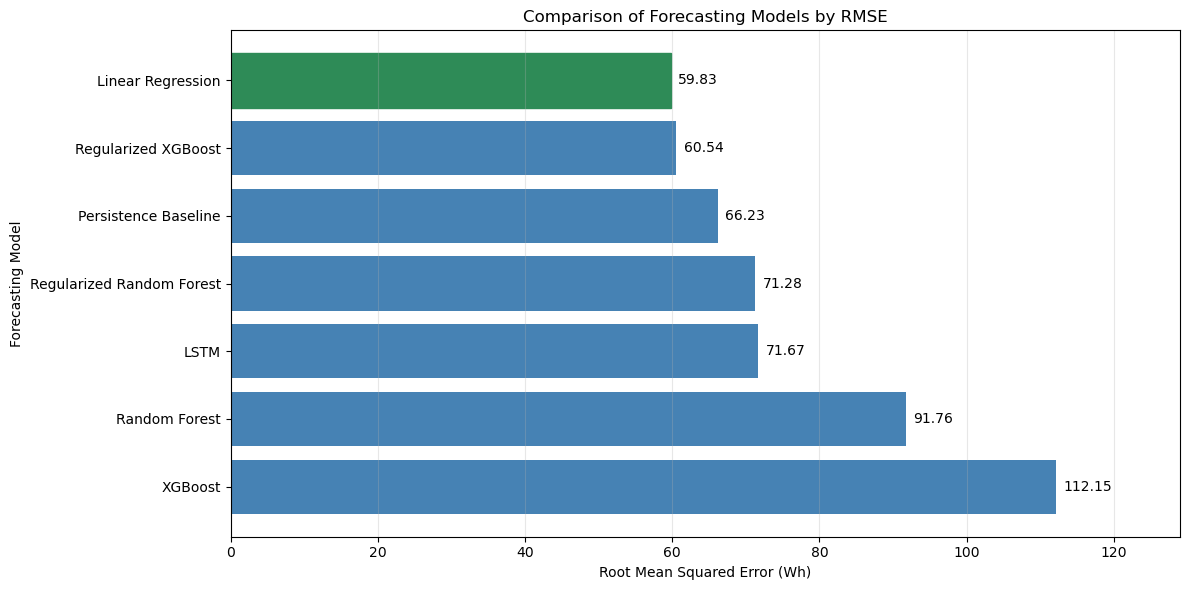

In [52]:
# Section 4.8.4: Final Model Performance Visualization

plt.figure(figsize=(12, 6))

bars = plt.barh(
    final_model_results["Model"],
    final_model_results["RMSE (Wh)"],
    color="steelblue"
)

# Highlight the best model
bars[0].set_color("seagreen")

plt.gca().invert_yaxis()

plt.title("Comparison of Forecasting Models by RMSE")
plt.xlabel("Root Mean Squared Error (Wh)")
plt.ylabel("Forecasting Model")

# Display RMSE values beside each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center"
    )

plt.xlim(0, final_model_results["RMSE (Wh)"].max() * 1.15)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/final_model_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.8.5 Interpretation of Final Model Comparison

The seven forecasting configurations were evaluated using the same 3,941 test observations to ensure a fair comparison.

Linear Regression achieved the lowest RMSE (59.83 Wh) and highest R² (0.5627), making it the best-performing model based on these two metrics. Regularized XGBoost achieved the lowest MAE (26.20 Wh), indicating the smallest average absolute prediction error.

The LSTM model achieved an RMSE of 63.11 Wh and an R² of 0.5135. Although it captured meaningful consumption patterns, it did not outperform the simpler Linear Regression model.

Regularization significantly improved the generalization performance of both Random Forest and XGBoost. Their original configurations performed poorly on unseen data, with negative R² values, whereas their regularized versions achieved positive R² values and substantially lower prediction errors.

Overall, the results demonstrate that model complexity does not necessarily guarantee better forecasting performance. Linear Regression is selected as the preferred model based on RMSE and R², while Regularized XGBoost remains a competitive alternative based on MAE.

# Section 5: Forecasting Results Visualization and Interpretation

## 5.1 Actual vs. Predicted Appliance Energy Consumption

This section examines the forecasting performance of the best-performing model, Linear Regression, by comparing predicted appliance energy consumption against actual observations from the testing dataset.

The objective is to evaluate how effectively the model captures variations in household electricity consumption over time.

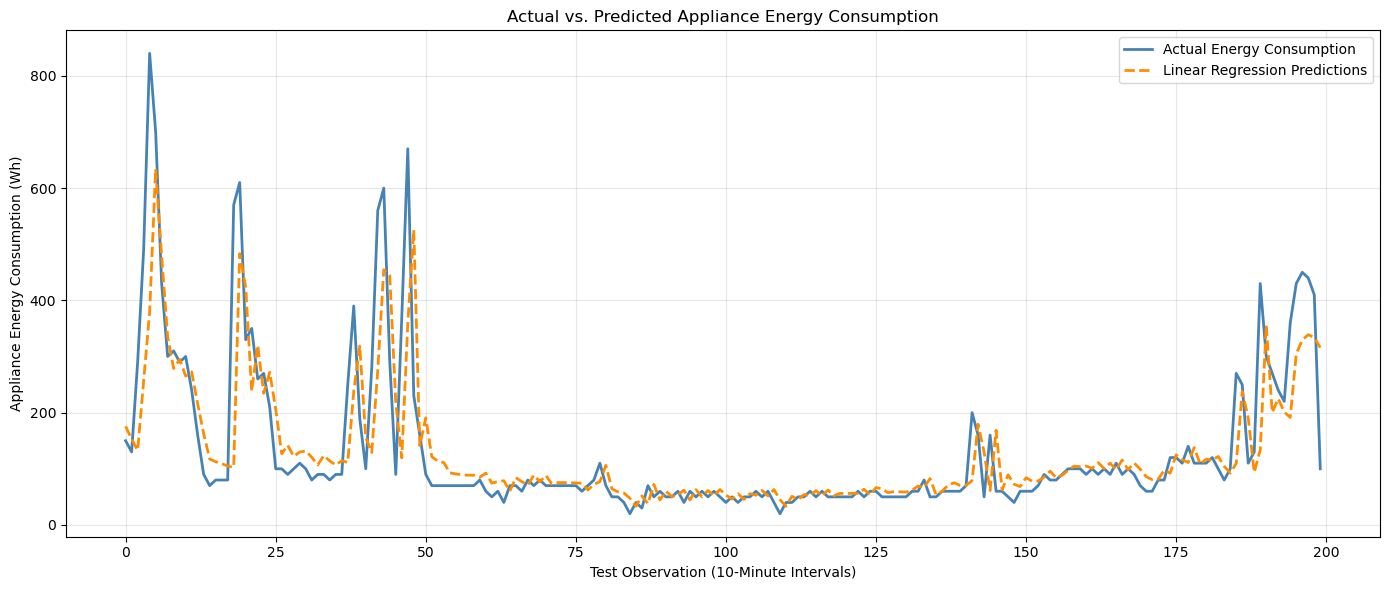

In [53]:
# Section 5.1.2: Actual vs. Predicted Energy Consumption

# Use the same test observations and predictions
# from the final aligned model comparison
actual_values = np.asarray(y_test_aligned)
predicted_values = np.asarray(y_pred_lr)[alignment_offset:]

# Select the first 200 observations for clearer visualization
n_points = 200

plt.figure(figsize=(14, 6))

plt.plot(
    actual_values[:n_points],
    label="Actual Energy Consumption",
    color="steelblue",
    linewidth=2
)

plt.plot(
    predicted_values[:n_points],
    label="Linear Regression Predictions",
    color="darkorange",
    linewidth=2,
    linestyle="--"
)

plt.title("Actual vs. Predicted Appliance Energy Consumption")
plt.xlabel("Test Observation (10-Minute Intervals)")
plt.ylabel("Appliance Energy Consumption (Wh)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/actual_vs_predicted_linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5.2 Residual Analysis

Residual analysis examines the differences between actual and predicted appliance energy consumption. It helps identify systematic prediction errors, unusual observations, and limitations in the forecasting model.

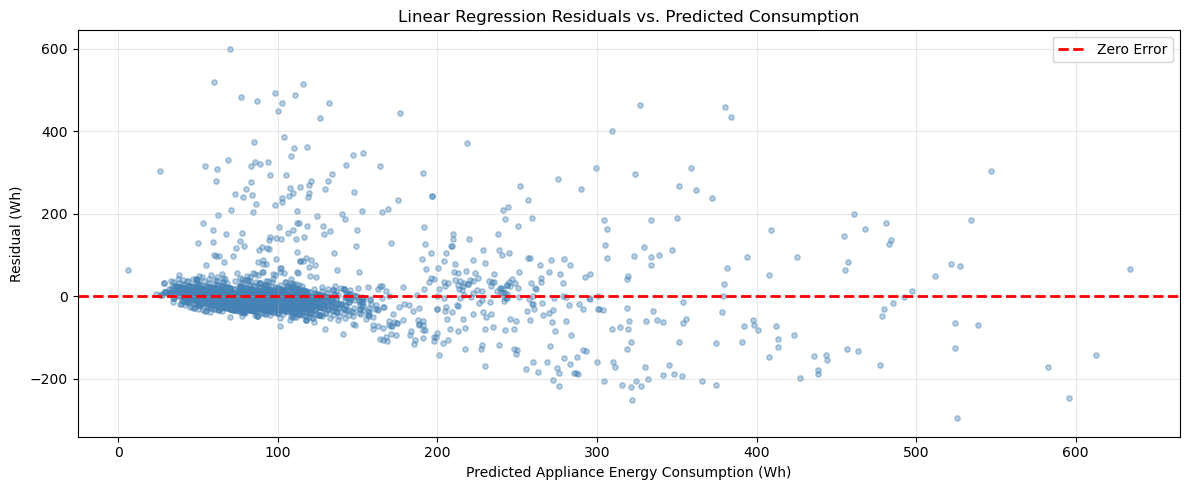

In [54]:
# Section 5.2.1: Linear Regression Residual Analysis

# Calculate residuals using aligned testing observations
lr_residuals = actual_values - predicted_values

plt.figure(figsize=(12, 5))

plt.scatter(
    predicted_values,
    lr_residuals,
    alpha=0.4,
    color="steelblue",
    s=15
)

# Reference line representing zero prediction error
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("Linear Regression Residuals vs. Predicted Consumption")
plt.xlabel("Predicted Appliance Energy Consumption (Wh)")
plt.ylabel("Residual (Wh)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/linear_regression_residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

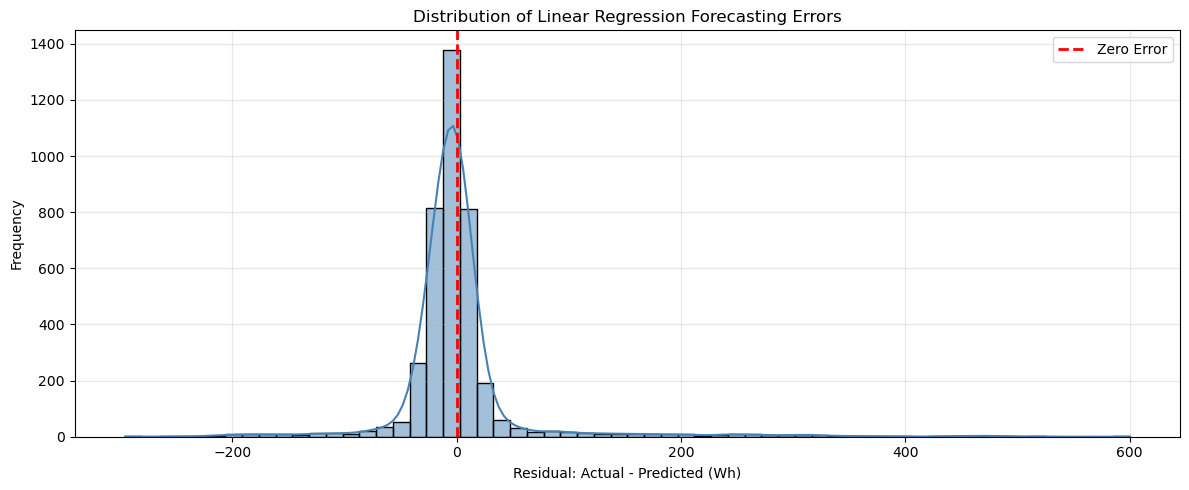

In [55]:
# Section 5.2.2: Distribution of Linear Regression Residuals

plt.figure(figsize=(12, 5))

sns.histplot(
    lr_residuals,
    bins=60,
    kde=True,
    color="steelblue"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("Distribution of Linear Regression Forecasting Errors")
plt.xlabel("Residual: Actual - Predicted (Wh)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../figure/linear_regression_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
# Section 5.3.1: Linear Regression Coefficients

lr_coefficients = pd.DataFrame({
    "Feature": X_train_forecast.columns,
    "Coefficient": lr_model.coef_
})

lr_coefficients["Absolute Coefficient"] = (
    lr_coefficients["Coefficient"].abs()
)

lr_coefficients = lr_coefficients.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(lr_coefficients.head(15).round(4))


,Feature,Coefficient,Absolute Coefficient
31,hour_cos,-12.9962,12.9962
30,hour_sin,-11.5847,11.5847
2,T1,-5.5192,5.5192
32,day_sin,-4.1929,4.1929
6,T3,3.8151,3.8151
4,T2,2.8152,2.8152
8,T4,-1.8330,1.8330
16,T8,1.8046,1.8046
20,T_out,1.7850,1.7850
3,RH_1,-1.6807,1.6807


In [57]:
# Section 5.3.2: Standardized Linear Regression Coefficients

# Calculate standard deviation of each training feature
feature_std = X_train_forecast.std()

# Calculate standardized coefficients
standardized_coefficients = pd.DataFrame({
    "Feature": X_train_forecast.columns,
    "Standardized Coefficient": (
        lr_model.coef_ * feature_std.values
    )
})

# Calculate absolute values for ranking
standardized_coefficients["Absolute Importance"] = (
    standardized_coefficients["Standardized Coefficient"].abs()
)

# Sort by absolute importance
standardized_coefficients = standardized_coefficients.sort_values(
    by="Absolute Importance",
    ascending=False
)

# Display the top 15 features
display(standardized_coefficients.head(15).round(4))

,Feature,Standardized Coefficient,Absolute Importance
0,Appliances,82.8289,82.8289
34,Appliances_lag_1,-28.0450,28.0450
37,Appliances_rolling_mean_3,18.7156,18.7156
31,hour_cos,-9.1863,9.1863
38,Appliances_rolling_mean_6,8.3231,8.3231
30,hour_sin,-8.1950,8.1950
20,T_out,7.3718,7.3718
2,T1,-6.7015,6.7015
35,Appliances_lag_3,-6.6290,6.6290
3,RH_1,-6.0365,6.0365


In [58]:
# Section 5.3.3: Check for Potential Target Leakage

print("Is 'Appliances' included in the input features?")
print("Appliances" in X_train_forecast.columns)

print("\nAppliance-related input features:")
print([
    col for col in X_train_forecast.columns
    if "Appliances" in col
])

print("\nFirst five input values and target values:")
display(
    pd.DataFrame({
        "Input_Appliances": X_train_forecast["Appliances"].iloc[:5].to_numpy(),
        "Target_Appliances": np.asarray(y_train_forecast)[:5]
    })
)

Is 'Appliances' included in the input features?
True

Appliance-related input features:
['Appliances', 'Appliances_lag_1', 'Appliances_lag_3', 'Appliances_lag_6', 'Appliances_rolling_mean_3', 'Appliances_rolling_mean_6']

First five input values and target values:


,Input_Appliances,Target_Appliances
0,60,60.0
1,60,60.0
2,60,70.0
3,70,230.0
4,230,580.0


In [59]:
# Section 5.3.4: Verify Forecasting Alignment

current_consumption = X_train_forecast["Appliances"].to_numpy()
target_consumption = np.asarray(y_train_forecast)

# For one-step-ahead forecasting, the target at time t
# should equal the input consumption at time t+1.
alignment_check = np.allclose(
    target_consumption[:-1],
    current_consumption[1:]
)

print("One-step-ahead alignment verified:", alignment_check)

print("\nFirst 10 observations:")
display(pd.DataFrame({
    "Current Consumption (Wh)": current_consumption[:10],
    "Next-Interval Target (Wh)": target_consumption[:10]
}))

One-step-ahead alignment verified: True

First 10 observations:


,Current Consumption (Wh),Next-Interval Target (Wh)
0,60,60.0
1,60,60.0
2,60,70.0
3,70,230.0
4,230,580.0
5,580,430.0
6,430,250.0
7,250,100.0
8,100,100.0
9,100,90.0


### 5.3.5 Forecasting Alignment Verification

The forecasting alignment check confirmed that the model predicts appliance energy consumption one time step (10 minutes) ahead.

The current appliance consumption is included among the input features, while the target represents consumption at the next observation. The verification returned `True`, confirming correct one-step-ahead alignment in the training data.

Therefore, including current appliance consumption as a predictor is appropriate for this forecasting task and does not, by itself, constitute target leakage.

### 5.4 Model Performance and Key Findings

#### 5.4.1 Interpretation of Forecasting Model Performance

Seven forecasting model configurations were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

**Linear Regression achieved the best overall forecasting performance**, recording an RMSE of 59.83 Wh, an MAE of 26.63 Wh, and an R² of 0.5627. This indicates that the model explains approximately 56.3% of the variation in appliance energy consumption within the evaluated test observations.

Regularized XGBoost performed comparably, achieving the lowest MAE of 26.20 Wh and an RMSE of 60.54 Wh. The LSTM model also demonstrated reasonable forecasting performance, with an RMSE of 63.11 Wh.

The Persistence Baseline recorded an RMSE of 66.23 Wh, indicating that the three leading models improved upon a simple forecasting approach based on recent consumption.

The original Random Forest and XGBoost models performed considerably worse, while their regularized versions showed improvements. This demonstrates the importance of controlling model complexity and evaluating generalization performance.

Overall, the results suggest that a relatively simple Linear Regression model can outperform more complex machine learning and deep learning approaches for this particular short-term forecasting task.

#### 5.4.2 Interpretation of Forecasting Errors and Residuals

The actual-versus-predicted consumption graph shows that Linear Regression generally follows the observed energy consumption pattern, particularly during periods of relatively stable demand. However, the model tends to underestimate some sudden consumption peaks.

The residual scatterplot reveals that prediction errors are not distributed uniformly across all consumption levels. Larger errors occur during periods of higher energy consumption, suggesting that the model has difficulty capturing abrupt changes in household appliance usage.

The residual distribution is strongly concentrated around zero, indicating that many predictions have relatively small errors. However, the distribution also contains long tails, reflecting occasional substantial forecasting errors.

Overall, these findings suggest that Linear Regression provides reasonable short-term energy consumption forecasts but remains less reliable during sudden changes in household electricity demand.

#### 5.4.3 Interpretation of Feature Importance

The standardized Linear Regression coefficients indicate that current appliance consumption and historical consumption features have substantial influence on the model's predictions.

Time-of-day features, particularly `hour_cos` and `hour_sin`, also contribute to forecasting, reflecting daily variations in household energy usage.

Outdoor temperature (`T_out`) is another relevant predictor, suggesting that environmental conditions may help explain changes in appliance energy consumption.

However, these coefficients represent statistical associations rather than causal relationships. Correlations between predictors may also affect their individual coefficient magnitudes.

Overall, recent consumption patterns and time-related features appear particularly relevant for predicting appliance energy consumption 10 minutes ahead.

## 6. Conclusions and Recommendations

### 6.1 Project Conclusion

This project developed and evaluated machine learning and deep learning models for predicting household appliance energy consumption 10 minutes ahead, using historical consumption, environmental measurements, and time-related features.

Seven forecasting model configurations were evaluated. Linear Regression achieved the best overall performance based on RMSE (59.83 Wh) and R² (0.5627), while Regularized XGBoost achieved the lowest MAE (26.20 Wh).

The findings demonstrate that simpler statistical models can outperform more complex approaches in short-term energy forecasting. They also highlight the importance of regularization, appropriate model evaluation, and historical consumption information.

Although the best-performing model captured a substantial proportion of consumption variability, forecasting sudden energy demand peaks remains challenging.

Overall, the project demonstrates the potential of data-driven forecasting to support smart home energy monitoring and short-term electricity demand prediction.

### 6.2 Recommendations and Future Improvements

Based on the findings of this project, the following improvements are recommended:

1. **Improve peak-demand forecasting:** Explore techniques that better capture sudden increases in appliance energy consumption, since these periods produced some of the largest prediction errors.

2. **Expand the dataset:** Evaluate the models using additional households and longer observation periods to determine whether their performance generalizes beyond the current dataset.

3. **Explore additional forecasting horizons:** Extend the analysis beyond 10-minute-ahead predictions to 30-minute and 1-hour forecasting horizons.

4. **Optimize model configurations:** Investigate further hyperparameter tuning and alternative feature-selection approaches to improve forecasting accuracy.

5. **Develop a practical monitoring application:** Integrate the best-performing model into a simple dashboard that displays recent consumption, predicted demand, and potential high-consumption periods.

These improvements could increase the reliability and practical usefulness of the forecasting system for smart home energy management.